# Evaluation Comparison

Load normalized evaluation artifacts from `data/outputs/runs`, summarize them across runs, and compare multilingual OxfordEval and GDEX performance with partially overlapping language bars.


In [23]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUNS_DIR = Path("data/outputs/runs")
LANGUAGE_ORDER = ["en", "hi", "uk"]
LANGUAGE_LABELS = {
    "en": "English",
    "hi": "Hindi",
    "uk": "Ukrainian",
}
LANGUAGE_COLORS = {
    "en": "#3563E9",
    "hi": "#17A34A",
    "uk": "#F59E0B",
}


In [24]:
def load_run_manifest(run_dir: Path) -> dict:
    manifest_path = run_dir / "manifest.json"
    if not manifest_path.exists():
        return {}
    return json.loads(manifest_path.read_text(encoding="utf-8"))


def build_model_label(manifest: dict, run_dir: Path) -> str:
    model = manifest.get("configs", {}).get("model", {})
    model_name = model.get("name")
    model_id = model.get("model_id")
    if model_name and model_id:
        return f"{model_name} ({model_id})"
    if model_name:
        return model_name
    return manifest.get("run_id", run_dir.name)


def build_run_label(manifest: dict, run_dir: Path) -> str:
    run_id = manifest.get("run_id") or run_dir.name
    return run_id.replace("_v1", "").replace("_", " ")


def load_evaluations(runs_dir: Path = RUNS_DIR) -> pd.DataFrame:
    rows = []
    for eval_path in sorted(runs_dir.glob("*/evaluations.jsonl")):
        run_dir = eval_path.parent
        manifest = load_run_manifest(run_dir)
        model = manifest.get("configs", {}).get("model", {})
        model_label = build_model_label(manifest, run_dir)
        run_label = build_run_label(manifest, run_dir)

        with eval_path.open("r", encoding="utf-8") as handle:
            for line in handle:
                if not line.strip():
                    continue
                row = json.loads(line)
                row["run_dir"] = run_dir.name
                row["run_label"] = run_label
                row["model_label"] = model_label
                row["model_name"] = model.get("name")
                row["model_id"] = model.get("model_id")
                row["has_manifest"] = bool(manifest)
                rows.append(row)

    if not rows:
        return pd.DataFrame()

    frame = pd.json_normalize(rows)
    if "language" in frame.columns:
        frame["language"] = frame["language"].astype(str)
    return frame


evaluations_df = load_evaluations()
evaluations_df.head()


,id,run_id,metric_name,metric_config_name,metric_prompt_version,language,lexical_item_id,generated_example_id,score,created_at,...,result.criteria.typical.reason,result.criteria.informative.label,result.criteria.informative.reason,result.criteria.intelligible.label,result.criteria.intelligible.reason,result.criterion_scores.typical,result.criterion_scores.informative,result.criterion_scores.intelligible,result.full_yes,metadata.criteria_order
0,d3282861-fa72-4075-a2fb-db377a512b27,ministral_augmented_eval_v1,oxfordeval,oxfordeval,oxfordeval_1,en,64ae4565e4f624d71c89c44addc3340a9e82e596,adapted-379fa3d8-6d9c-4e85-8e77-d9674c02bf63,1.000000,2026-03-29T13:50:33.050753Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4a63bd36-ffeb-49c9-840b-c922f527b329,ministral_augmented_eval_v1,gdex,gdex,gdex_1,en,64ae4565e4f624d71c89c44addc3340a9e82e596,adapted-379fa3d8-6d9c-4e85-8e77-d9674c02bf63,1.000000,2026-03-29T13:50:34.887141Z,...,The sentence illustrates the concept of using ...,yes,It clearly contrasts 'indirection' with its an...,yes,The vocabulary is simple and the sentence stru...,1.0,1.0,1.0,True,"[typical, informative, intelligible]"
2,c51d1495-c103-4a7a-a71d-cb98d7529575,ministral_augmented_eval_v1,oxfordeval,oxfordeval,oxfordeval_1,en,887e4121396f30eebf5f8d41a1af7719fad7015b,adapted-8d8cecc5-d59d-4c4a-b7ee-73aded4b0770,0.000000,2026-03-29T13:50:36.323057Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12583456-b9cb-4d5c-96af-f07120b49ed0,ministral_augmented_eval_v1,gdex,gdex,gdex_1,en,887e4121396f30eebf5f8d41a1af7719fad7015b,adapted-8d8cecc5-d59d-4c4a-b7ee-73aded4b0770,0.833333,2026-03-29T13:50:38.144254Z,...,The sentence uses 'evidently' as a sentential ...,somewhat,While it shows the word used to express clear ...,yes,"The sentence is short, uses common vocabulary,...",1.0,0.5,1.0,False,"[typical, informative, intelligible]"
4,193613c1-5db4-40eb-847a-48e3f5c9fb5b,ministral_augmented_eval_v1,oxfordeval,oxfordeval,oxfordeval_1,en,6a7be4bfc052ce5a099a7a4fd289e67d64d5b9cb,adapted-78578140-4948-42bd-9ef4-54b0dab29b08,1.000000,2026-03-29T13:50:40.900095Z,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
def summarize_metrics(evaluations: pd.DataFrame) -> pd.DataFrame:
    if evaluations.empty:
        return pd.DataFrame()

    summary = (
        evaluations.groupby(
            ["metric_name", "run_id", "run_label", "model_label", "language"],
            dropna=False,
        )
        .agg(
            n=("score", "size"),
            mean_score=("score", "mean"),
        )
        .reset_index()
    )
    summary["agreement_pct"] = summary["mean_score"] * 100
    summary["display_label"] = summary["run_label"] + "\n" + summary["model_label"]
    summary["language_order"] = summary["language"].apply(
        lambda value: LANGUAGE_ORDER.index(value) if value in LANGUAGE_ORDER else len(LANGUAGE_ORDER)
    )
    return summary.sort_values(
        ["metric_name", "run_label", "language_order"],
        ascending=[True, True, True],
    )


metric_summary = summarize_metrics(evaluations_df)
metric_summary


,metric_name,run_id,run_label,model_label,language,n,mean_score,agreement_pct,display_label,language_order
0,gdex,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,en,10,0.816667,81.666667,ministral augmented eval\nministral_augmented_...,0
1,gdex,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,hi,10,0.633333,63.333333,ministral augmented eval\nministral_augmented_...,1
2,gdex,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,uk,10,0.683333,68.333333,ministral augmented eval\nministral_augmented_...,2
3,gdex,ministral_baseline_eval_v1,ministral baseline eval,ministral_baseline_eval_v1,en,10,0.716667,71.666667,ministral baseline eval\nministral_baseline_ev...,0
4,gdex,ministral_baseline_eval_v1,ministral baseline eval,ministral_baseline_eval_v1,hi,10,0.416667,41.666667,ministral baseline eval\nministral_baseline_ev...,1
5,gdex,ministral_baseline_eval_v1,ministral baseline eval,ministral_baseline_eval_v1,uk,10,0.650000,65.000000,ministral baseline eval\nministral_baseline_ev...,2
6,oxfordeval,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,en,10,0.400000,40.000000,ministral augmented eval\nministral_augmented_...,0
7,oxfordeval,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,hi,10,0.600000,60.000000,ministral augmented eval\nministral_augmented_...,1
8,oxfordeval,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,uk,10,0.400000,40.000000,ministral augmented eval\nministral_augmented_...,2
9,oxfordeval,ministral_baseline_eval_v1,ministral baseline eval,ministral_baseline_eval_v1,en,10,0.300000,30.000000,ministral baseline eval\nministral_baseline_ev...,0


,run_id,model_label,language,n,agreement_pct
6,ministral_augmented_eval_v1,ministral_augmented_eval_v1,en,10,40.0
7,ministral_augmented_eval_v1,ministral_augmented_eval_v1,hi,10,60.0
8,ministral_augmented_eval_v1,ministral_augmented_eval_v1,uk,10,40.0
9,ministral_baseline_eval_v1,ministral_baseline_eval_v1,en,10,30.0
10,ministral_baseline_eval_v1,ministral_baseline_eval_v1,hi,10,40.0
11,ministral_baseline_eval_v1,ministral_baseline_eval_v1,uk,10,40.0


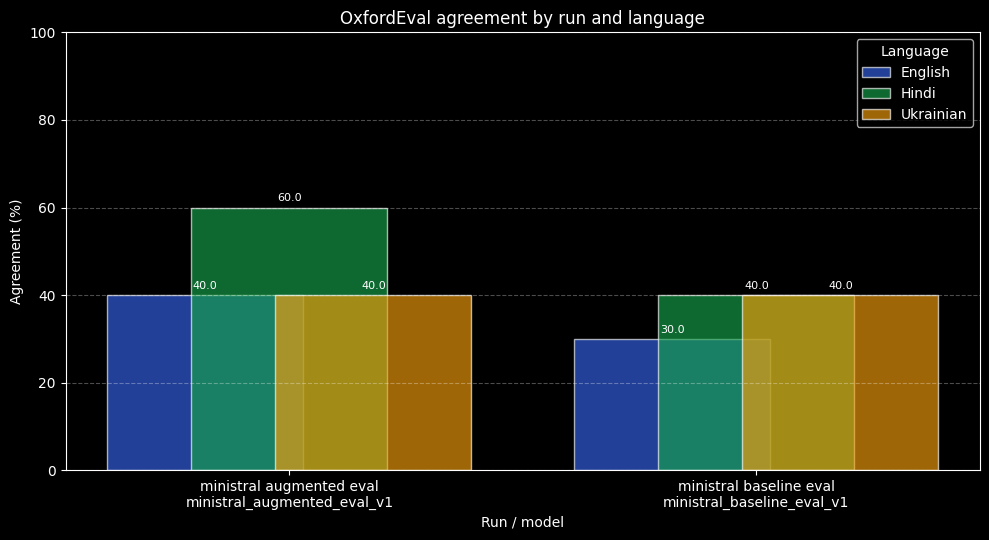

In [26]:
def plot_oxfordeval_agreement(summary: pd.DataFrame) -> pd.DataFrame:
    oxford = summary[summary["metric_name"] == "oxfordeval"].copy()
    if oxford.empty:
        raise ValueError("No OxfordEval rows found in the loaded evaluation artifacts.")

    run_rows = (
        oxford[["run_id", "run_label", "model_label", "display_label"]]
        .drop_duplicates()
        .sort_values(["run_label", "model_label"])
        .reset_index(drop=True)
    )
    languages = [language for language in LANGUAGE_ORDER if language in set(oxford["language"]) ]
    if not languages:
        languages = sorted(oxford["language"].dropna().unique().tolist())

    x_positions = np.arange(len(run_rows))
    offsets = np.linspace(-0.18, 0.18, num=max(len(languages), 1))
    bar_width = 0.42

    fig, ax = plt.subplots(figsize=(max(10, len(run_rows) * 3.2), 5.5))
    for offset, language in zip(offsets, languages):
        language_rows = (
            oxford[oxford["language"] == language]
            .set_index("run_id")
            .reindex(run_rows["run_id"])
        )
        bars = ax.bar(
            x_positions + offset,
            language_rows["agreement_pct"],
            width=bar_width,
            label=LANGUAGE_LABELS.get(language, language),
            color=LANGUAGE_COLORS.get(language),
            alpha=0.65,
            edgecolor="white",
            linewidth=1.0,
        )
        for bar, value in zip(bars, language_rows["agreement_pct"]):
            if pd.notna(value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    value + 1,
                    f"{value:.1f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

    ax.set_title("OxfordEval agreement by run and language")
    ax.set_xlabel("Run / model")
    ax.set_ylabel("Agreement (%)")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(run_rows["display_label"])
    ax.set_ylim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend(title="Language")
    plt.tight_layout()
    return oxford[["run_id", "model_label", "language", "n", "agreement_pct"]]


plot_oxfordeval_agreement(metric_summary)


In [27]:
def summarize_gdex_criteria(evaluations: pd.DataFrame) -> pd.DataFrame:
    gdex = evaluations[evaluations["metric_name"] == "gdex"].copy()
    if gdex.empty:
        return pd.DataFrame()

    criterion_columns = {
        "Typicality": "result.criterion_scores.typical",
        "Informativeness": "result.criterion_scores.informative",
        "Intelligibility": "result.criterion_scores.intelligible",
    }

    missing = [column for column in criterion_columns.values() if column not in gdex.columns]
    if missing:
        raise ValueError(f"Missing GDEX criterion score columns: {missing}")

    rows = []
    for criterion_name, column in criterion_columns.items():
        summary = (
            gdex.groupby(["run_id", "run_label", "model_label", "language"], dropna=False)[column]
            .mean()
            .reset_index(name="mean_score")
        )
        summary["criterion"] = criterion_name
        rows.append(summary)

    criterion_summary = pd.concat(rows, ignore_index=True)
    criterion_summary["percentage"] = criterion_summary["mean_score"] * 100
    criterion_summary["language_order"] = criterion_summary["language"].apply(
        lambda value: LANGUAGE_ORDER.index(value) if value in LANGUAGE_ORDER else len(LANGUAGE_ORDER)
    )
    return criterion_summary.sort_values(
        ["run_label", "criterion", "language_order"],
        ascending=[True, True, True],
    )


gdex_summary = summarize_gdex_criteria(evaluations_df)
gdex_summary


,run_id,run_label,model_label,language,mean_score,criterion,percentage,language_order
6,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,en,0.70,Informativeness,70.0,0
7,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,hi,0.60,Informativeness,60.0,1
8,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,uk,0.70,Informativeness,70.0,2
12,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,en,1.00,Intelligibility,100.0,0
13,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,hi,0.65,Intelligibility,65.0,1
14,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,uk,0.70,Intelligibility,70.0,2
0,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,en,0.75,Typicality,75.0,0
1,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,hi,0.65,Typicality,65.0,1
2,ministral_augmented_eval_v1,ministral augmented eval,ministral_augmented_eval_v1,uk,0.65,Typicality,65.0,2
9,ministral_baseline_eval_v1,ministral baseline eval,ministral_baseline_eval_v1,en,0.65,Informativeness,65.0,0


,run_id,model_label,language,criterion,percentage
6,ministral_augmented_eval_v1,ministral_augmented_eval_v1,en,Informativeness,70.0
7,ministral_augmented_eval_v1,ministral_augmented_eval_v1,hi,Informativeness,60.0
8,ministral_augmented_eval_v1,ministral_augmented_eval_v1,uk,Informativeness,70.0
12,ministral_augmented_eval_v1,ministral_augmented_eval_v1,en,Intelligibility,100.0
13,ministral_augmented_eval_v1,ministral_augmented_eval_v1,hi,Intelligibility,65.0
14,ministral_augmented_eval_v1,ministral_augmented_eval_v1,uk,Intelligibility,70.0
0,ministral_augmented_eval_v1,ministral_augmented_eval_v1,en,Typicality,75.0
1,ministral_augmented_eval_v1,ministral_augmented_eval_v1,hi,Typicality,65.0
2,ministral_augmented_eval_v1,ministral_augmented_eval_v1,uk,Typicality,65.0
9,ministral_baseline_eval_v1,ministral_baseline_eval_v1,en,Informativeness,65.0


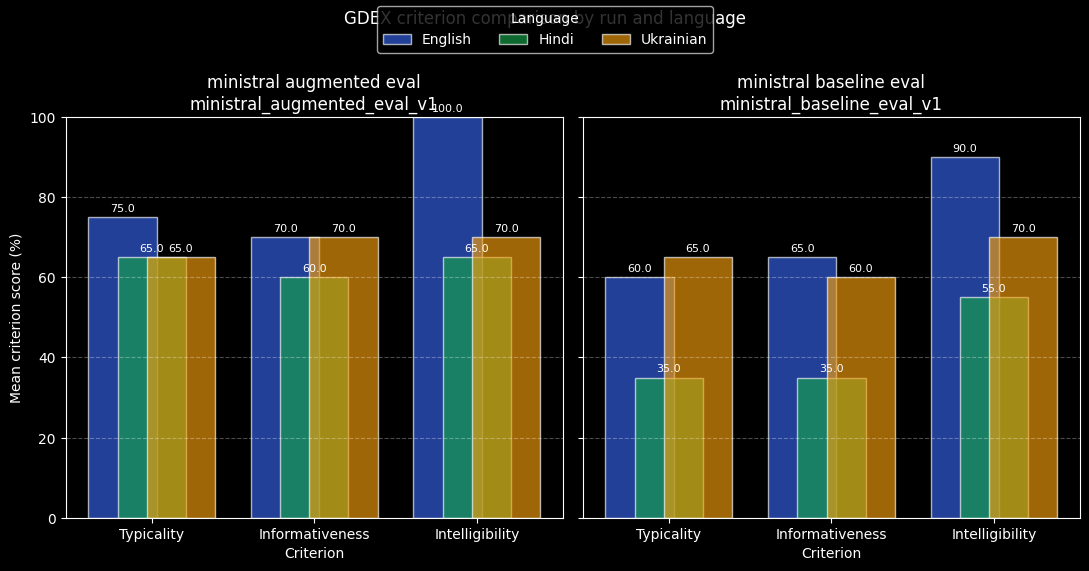

In [28]:
def plot_gdex_criteria(summary: pd.DataFrame) -> pd.DataFrame:
    if summary.empty:
        raise ValueError("No GDEX rows found in the loaded evaluation artifacts.")

    criteria_order = ["Typicality", "Informativeness", "Intelligibility"]
    run_rows = (
        summary[["run_id", "run_label", "model_label"]]
        .drop_duplicates()
        .sort_values(["run_label", "model_label"])
        .reset_index(drop=True)
    )
    languages = [language for language in LANGUAGE_ORDER if language in set(summary["language"]) ]
    if not languages:
        languages = sorted(summary["language"].dropna().unique().tolist())

    fig, axes = plt.subplots(
        1,
        len(run_rows),
        figsize=(max(7, len(run_rows) * 5.5), 5.5),
        sharey=True,
    )
    if len(run_rows) == 1:
        axes = [axes]

    x_positions = np.arange(len(criteria_order))
    offsets = np.linspace(-0.18, 0.18, num=max(len(languages), 1))
    bar_width = 0.42

    for ax, run_row in zip(axes, run_rows.itertuples(index=False)):
        run_summary = summary[summary["run_id"] == run_row.run_id]
        for offset, language in zip(offsets, languages):
            language_rows = (
                run_summary[run_summary["language"] == language]
                .set_index("criterion")
                .reindex(criteria_order)
            )
            bars = ax.bar(
                x_positions + offset,
                language_rows["percentage"],
                width=bar_width,
                label=LANGUAGE_LABELS.get(language, language),
                color=LANGUAGE_COLORS.get(language),
                alpha=0.65,
                edgecolor="white",
                linewidth=1.0,
            )
            for bar, value in zip(bars, language_rows["percentage"]):
                if pd.notna(value):
                    ax.text(
                        bar.get_x() + bar.get_width() / 2,
                        value + 1,
                        f"{value:.1f}",
                        ha="center",
                        va="bottom",
                        fontsize=8,
                    )

        ax.set_title(f"{run_row.run_label}\n{run_row.model_label}")
        ax.set_xticks(x_positions)
        ax.set_xticklabels(criteria_order)
        ax.set_ylim(0, 100)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_xlabel("Criterion")

    axes[0].set_ylabel("Mean criterion score (%)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Language", loc="upper center", ncol=max(len(languages), 1))
    fig.suptitle("GDEX criterion comparison by run and language", y=1.03)
    plt.tight_layout()
    return summary[["run_id", "model_label", "language", "criterion", "percentage"]]


plot_gdex_criteria(gdex_summary)
